# 15 隙間倍率6条件の比較

元の全館空調検討で用いた倍率0、0.5、1、2、4、8の比較手順を、小規模換気モデルで学ぶ。

## 到達目標
倍率はC値そのものではない。この教材は住宅の年間負荷を再現しない。C値への換算には床面積、測定圧力、指数と開口の配分が必要。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/15/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "15"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'15_gap_x0': {'builder': {},
               'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                        'end': '2026-01-01T23:00:00',
                                        'length': 24,
                                        'timestep': 3600}},
               'nodes': [{'key': 'windward',
                          'p': [2.0,
                                2.2588190451025207,
                                2.5,
                                2.7071067811865475,
                                2.8660254037844384,
                                2.965925826289068,
                                3.0,
                                2.965925826289068,
                                2.866025403784439,
                                2.7071067811865475,
                                2.5,
                                2.258819045102521,
                                2.0,
                                1.7411809548974797,
                                1.5,
                                1.2928932188134525,
                                1.1339745962155616,
                                1.0340741737109318,
                                1.0,
                                1.0340741737109316,
                                1.1339745962155614,
                                1.2928932188134523,
                                1.4999999999999996,
                                1.7411809548974793],
                          't': 5},
                         {'key': 'leeward', 'p': 0, 't': 5},
                         {'key': 'room', 'p': 0, 't': 20, 'calc_p': False}],
               'ventilation_branches': [{'key': 'windward->room',
                                         'source': 'windward',
                                         'target': 'room',
                                         'vol': 0},
                                        {'key': 'room->leeward',
                                         'source': 'room',
                                         'target': 'leeward',
                                         'vol': 0}],
               'thermal_branches': []},
 '15_gap_x0.5': {'builder': {},
                 'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                          'end': '2026-01-01T23:00:00',
                                          'length': 24,
                                          'timestep': 3600}},
                 'nodes': [{'key': 'windward',
                            'p': [2.0,
                                  2.2588190451025207,
                                  2.5,
                                  2.7071067811865475,
                                  2.8660254037844384,
                                  2.965925826289068,
                                  3.0,
                                  2.965925826289068,
                                  2.866025403784439,
                                  2.7071067811865475,
                                  2.5,
                                  2.258819045102521,
                                  2.0,
                                  1.7411809548974797,
                                  1.5,
                                  1.2928932188134525,
                                  1.1339745962155616,
                                  1.0340741737109318,
                                  1.0,
                                  1.0340741737109316,
                                  1.1339745962155614,
                                  1.2928932188134523,
                                  1.4999999999999996,
                                  1.7411809548974793],
                            't': 5},
                           {'key': 'leeward', 'p': 0, 't': 5},
                           {'key': 'room', 'p': 0, 't': 20, 'calc_p': True}],
                 'ventilation_branches': [{'key': 'windward->room',
                                           'source': 'windward',
                                           'target': 'room',
                                           'type': 'gap',
                                           'a': 0.005,
                                           'n': 1.5384615384615383},
                                          {'key': 'room->leeward',
                                           'source': 'room',
                                           'target': 'leeward',
                                           'type': 'gap',
                                           'a': 0.005,
                                           'n': 1.5384615384615383}],
                 'thermal_branches': []},
 '15_gap_x1': {'builder': {},
               'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                        'end': '2026-01-01T23:00:00',
                                        'length': 24,
                                        'timestep': 3600}},
               'nodes': [{'key': 'windward',
                          'p': [2.0,
                                2.2588190451025207,
                                2.5,
                                2.7071067811865475,
                                2.8660254037844384,
                                2.965925826289068,
                                3.0,
                                2.965925826289068,
                                2.866025403784439,
                                2.7071067811865475,
                                2.5,
                                2.258819045102521,
                                2.0,
                                1.7411809548974797,
                                1.5,
                                1.2928932188134525,
                                1.1339745962155616,
                                1.0340741737109318,
                                1.0,
                                1.0340741737109316,
                                1.1339745962155614,
                                1.2928932188134523,
                                1.4999999999999996,
                                1.7411809548974793],
                          't': 5},
                         {'key': 'leeward', 'p': 0, 't': 5},
                         {'key': 'room', 'p': 0, 't': 20, 'calc_p': True}],
               'ventilation_branches': [{'key': 'windward->room',
                                         'source': 'windward',
                                         'target': 'room',
                                         'type': 'gap',
                                         'a': 0.01,
                                         'n': 1.5384615384615383},
                                        {'key': 'room->leeward',
                                         'source': 'room',
                                         'target': 'leeward',
                                         'type': 'gap',
                                         'a': 0.01,
                                         'n': 1.5384615384615383}],
               'thermal_branches': []},
 '15_gap_x2': {'builder': {},
               'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                        'end': '2026-01-01T23:00:00',
                                        'length': 24,
                                        'timestep': 3600}},
               'nodes': [{'key': 'windward',
                          'p': [2.0,
                                2.2588190451025207,
                                2.5,
                                2.7071067811865475,
                                2.8660254037844384,
                                2.965925826289068,
                                3.0,
                                2.965925826289068,
                                2.866025403784439,
                                2.7071067811865475,
                                2.5,
                                2.258819045102521,
                                2.0,
                                1.7411809548974797,
                                1.5,
                                1.2928932188134525,
                                1.1339745962155616,
                                1.0340741737109318,
                                1.0,
                                1.0340741737109316,
                                1.1339745962155614,
                                1.2928932188134523,
                                1.4999999999999996,
                                1.7411809548974793],
                          't': 5},
                         {'key': 'leeward', 'p': 0, 't': 5},
                         {'key': 'room', 'p': 0, 't': 20, 'calc_p': True}],
               'ventilation_branches': [{'key': 'windward->room',
                                         'source': 'windward',
                                         'target': 'room',
                                         'type': 'gap',
                                         'a': 0.02,
                                         'n': 1.5384615384615383},
                                        {'key': 'room->leeward',
                                         'source': 'room',
                                         'target': 'leeward',
                                         'type': 'gap',
                                         'a': 0.02,
                                         'n': 1.5384615384615383}],
               'thermal_branches': []},
 '15_gap_x4': {'builder': {},
               'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                        'end': '2026-01-01T23:00:00',
                                        'length': 24,
                                        'timestep': 3600}},
               'nodes': [{'key': 'windward',
                          'p': [2.0,
                                2.2588190451025207,
                                2.5,
                                2.7071067811865475,
                                2.8660254037844384,
                                2.965925826289068,
                                3.0,
                                2.965925826289068,
                                2.866025403784439,
                                2.7071067811865475,
                                2.5,
                                2.258819045102521,
                                2.0,
                                1.7411809548974797,
                                1.5,
                                1.2928932188134525,
                                1.1339745962155616,
                                1.0340741737109318,
                                1.0,
                                1.0340741737109316,
                                1.1339745962155614,
                                1.2928932188134523,
                                1.4999999999999996,
                                1.7411809548974793],
                          't': 5},
                         {'key': 'leeward', 'p': 0, 't': 5},
                         {'key': 'room', 'p': 0, 't': 20, 'calc_p': True}],
               'ventilation_branches': [{'key': 'windward->room',
                                         'source': 'windward',
                                         'target': 'room',
                                         'type': 'gap',
                                         'a': 0.04,
                                         'n': 1.5384615384615383},
                                        {'key': 'room->leeward',
                                         'source': 'room',
                                         'target': 'leeward',
                                         'type': 'gap',
                                         'a': 0.04,
                                         'n': 1.5384615384615383}],
               'thermal_branches': []},
 '15_gap_x8': {'builder': {},
               'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                        'end': '2026-01-01T23:00:00',
                                        'length': 24,
                                        'timestep': 3600}},
               'nodes': [{'key': 'windward',
                          'p': [2.0,
                                2.2588190451025207,
                                2.5,
                                2.7071067811865475,
                                2.8660254037844384,
                                2.965925826289068,
                                3.0,
                                2.965925826289068,
                                2.866025403784439,
                                2.7071067811865475,
                                2.5,
                                2.258819045102521,
                                2.0,
                                1.7411809548974797,
                                1.5,
                                1.2928932188134525,
                                1.1339745962155616,
                                1.0340741737109318,
                                1.0,
                                1.0340741737109316,
                                1.1339745962155614,
                                1.2928932188134523,
                                1.4999999999999996,
                                1.7411809548974793],
                          't': 5},
                         {'key': 'leeward', 'p': 0, 't': 5},
                         {'key': 'room', 'p': 0, 't': 20, 'calc_p': True}],
               'ventilation_branches': [{'key': 'windward->room',
                                         'source': 'windward',
                                         'target': 'room',
                                         'type': 'gap',
                                         'a': 0.08,
                                         'n': 1.5384615384615383},
                                        {'key': 'room->leeward',
                                         'source': 'room',
                                         'target': 'leeward',
                                         'type': 'gap',
                                         'a': 0.08,
                                         'n': 1.5384615384615383}],
               'thermal_branches': []}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


15_gap_x0 artifacts.1794699507923.output.2a9ee7a5639449edbe855d3345b5fe38


15_gap_x0.5 artifacts.1794699508946.output.e870711d304249da938a6d5a330be7ed


15_gap_x1 artifacts.1794699509965.output.ed249ba3a6b74b80b711f91c68154cfa


15_gap_x2 artifacts.1794699510983.output.fff3b22c73b0481799dfc07dd2781981


15_gap_x4 artifacts.1794699512003.output.a54fa466a33245d384c14fd8950080ca


15_gap_x8 artifacts.1794699513024.output.4e205b4b563c4fb08d9ce2edf9e6a886


15_gap_x0 全流量が入力で0。換気系列は出力されない境界ケースです。


,room->leeward,windward->room
time,,
2026-01-01 00:00:00,0.005000,0.005000
2026-01-01 01:00:00,0.005412,0.005412
2026-01-01 02:00:00,0.005780,0.005780
2026-01-01 03:00:00,0.006087,0.006087
2026-01-01 04:00:00,0.006317,0.006317


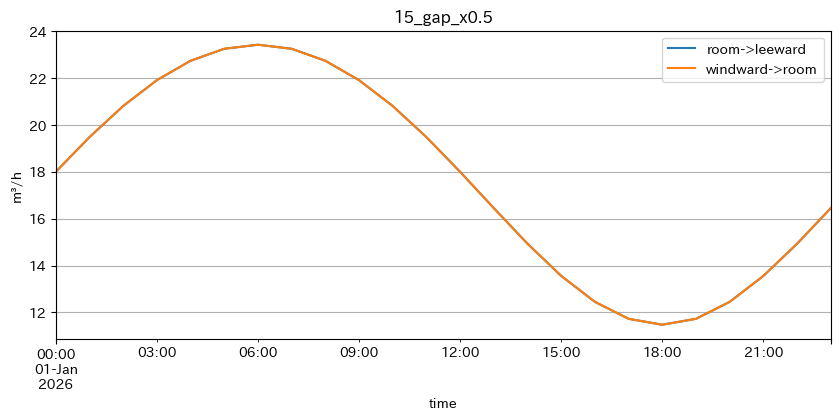

,room->leeward,windward->room
time,,
2026-01-01 00:00:00,0.010000,0.010000
2026-01-01 01:00:00,0.010823,0.010823
2026-01-01 02:00:00,0.011561,0.011561
2026-01-01 03:00:00,0.012175,0.012175
2026-01-01 04:00:00,0.012635,0.012635


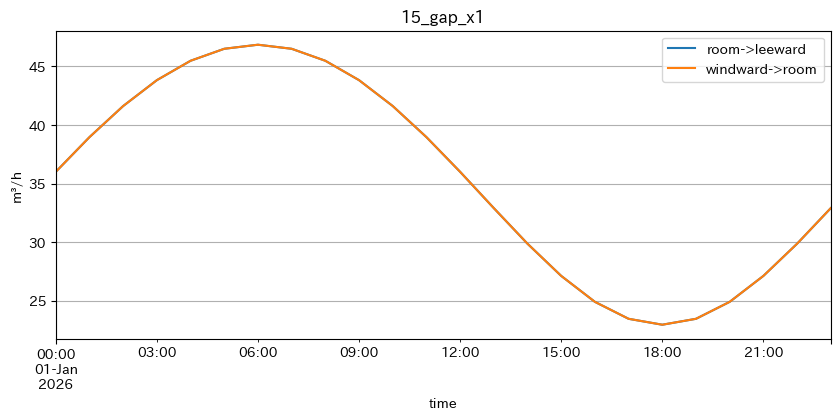

,room->leeward,windward->room
time,,
2026-01-01 00:00:00,0.020000,0.020000
2026-01-01 01:00:00,0.021646,0.021646
2026-01-01 02:00:00,0.023122,0.023122
2026-01-01 03:00:00,0.024349,0.024349
2026-01-01 04:00:00,0.025269,0.025269


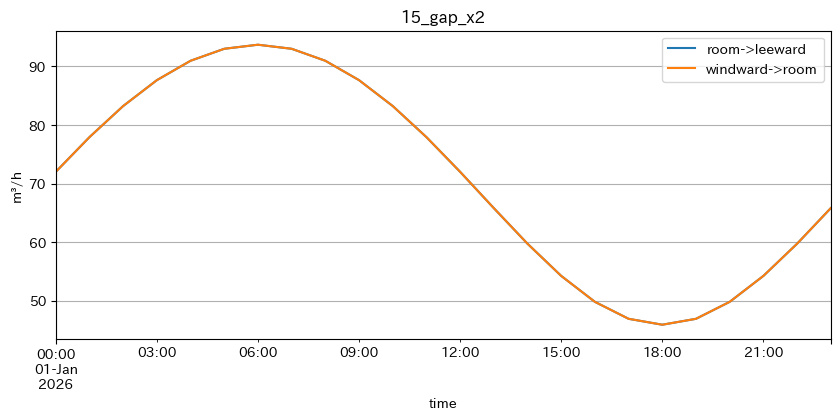

,room->leeward,windward->room
time,,
2026-01-01 00:00:00,0.040000,0.040000
2026-01-01 01:00:00,0.043293,0.043293
2026-01-01 02:00:00,0.046244,0.046244
2026-01-01 03:00:00,0.048699,0.048699
2026-01-01 04:00:00,0.050539,0.050539


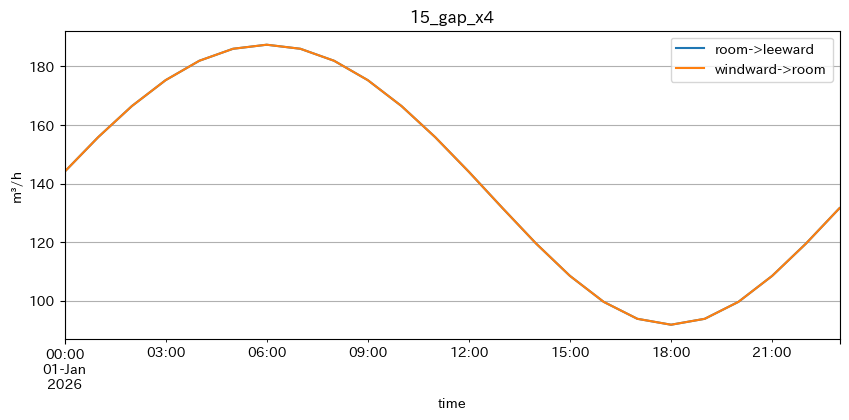

,room->leeward,windward->room
time,,
2026-01-01 00:00:00,0.080000,0.080000
2026-01-01 01:00:00,0.086585,0.086585
2026-01-01 02:00:00,0.092487,0.092487
2026-01-01 03:00:00,0.097398,0.097398
2026-01-01 04:00:00,0.101077,0.101077


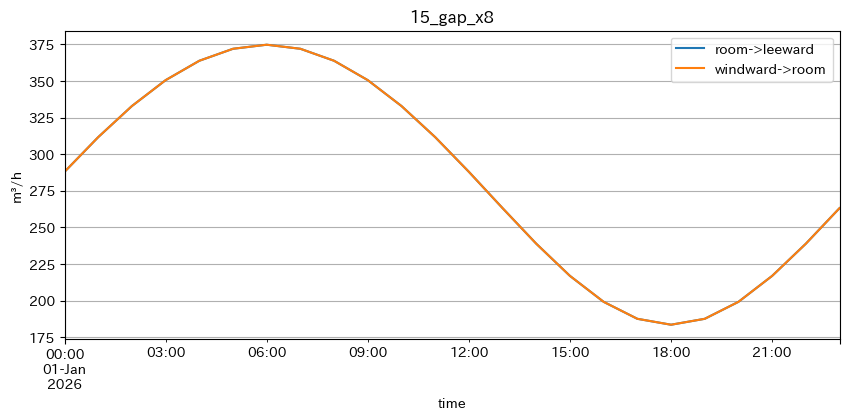

In [5]:
frames = {}
for name, result in results.items():
    frame = result.get_series_df("vent_flow_rate", raise_on_error=True) if "vent_flow_rate" in result.result_files else None
    if name == "15_gap_x0" and (frame is None or frame.empty):
        # 全流量が固定0で圧力の未知量もないため、engineは換気系列を出力しない。
        # 計算結果として0系列を捏造せず、境界ケースとして表示だけ分ける。
        assert all(b.get("vol") == 0 for b in configs[name]["ventilation_branches"])
        assert not any(n.get("calc_p",False) for n in configs[name]["nodes"])
        print(name, "全流量が入力で0。換気系列は出力されない境界ケースです。")
        continue
    assert frame is not None and not frame.empty
    assert np.isfinite(frame.to_numpy()).all()
    frames[name] = frame
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_vent_flow_rate.csv"),encoding="utf-8-sig")
    ax = (frame * 3600).plot(title=name,figsize=(10,4),grid=True,ylabel="m³/h")
    ax.figure.savefig(OUTPUT / (name + "_flow.png"),dpi=140,bbox_inches="tight")
    plt.show()


## 確認・発展
年間モデルに適用する際は倍率以外の気象・運転条件のハッシュを一致させる。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S010 Untitled8.ipynb
- S182 240310_集合住宅向け床吹出型全館空調_モデル化_K_1.ipynb
- S183 240310_集合住宅向け床吹出型全館空調_モデル化_K_2.ipynb
- S184 240310_集合住宅向け床吹出型全館空調_モデル化_K_3.ipynb
- S185 240310_集合住宅向け床吹出型全館空調_モデル化_K_4.ipynb
- S186 240310_集合住宅向け床吹出型全館空調_モデル化_K_5.ipynb
- S187 240310_集合住宅向け床吹出型全館空調_モデル化_M-1.ipynb
- S188 240310_集合住宅向け床吹出型全館空調_モデル化_M-2.ipynb
- S189 240310_集合住宅向け床吹出型全館空調_モデル化_SC.ipynb
- S330 Untitled0.ipynb
- S369 Untitled0.ipynb
- S380 251207_vtsimnx_test.ipynb

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。